# Análisis del texto: volumen, calidad y ruido

**Autor:** IagoVarelaR  
**Issue:** #21

## Objetivo

Entender cómo es el texto disponible y medir su ruido para decidir
las reglas de limpieza de la #7 y las estrategias de la #23.

## Preguntas

1. ¿Cuántos posts y caracteres tiene cada usuario?
2. ¿Cómo se comparan train y test?
3. ¿Cuántos usuarios no tienen posts o tienen muy pocos?
4. ¿Cuánto afectan los duplicados, vacíos, textos eliminados, URLs,
   markdown, citas, copypastas y posibles bots?
5. ¿Hay textos o usuarios que no escriben principalmente en inglés?
6. ¿Se relaciona el volumen de texto con algún rasgo?
7. ¿Qué reglas de limpieza sugiere cada hallazgo y qué impacto tendrían?

Cada tabla o gráfica irá acompañada de una interpretación y una
implicación práctica. Las conclusiones clave se resumirán en
`ANALISIS.md`.

**Estado:** análisis en curso.

**Dependencias adicionales del análisis:** `matplotlib==3.11.2` y `langdetect==1.0.9`.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

print("Repositorio:", REPO)

Repositorio: C:\Users\usuario\Desktop\IA\4º\Primer cuatri\TecLin\RETO FINAL\TecLin_Final_Boss


In [2]:
import re
from collections import Counter, defaultdict
from time import perf_counter

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from src.config import POSTS_PARQUET, SEED, TRAITS
from src.data import cargar_autores

train, test = cargar_autores()

usuarios_train = set(train["username"])
usuarios_test = set(test["username"])
usuarios_esperados = usuarios_train | usuarios_test

parquet = pq.ParquetFile(POSTS_PARQUET)

print(f"Train: {len(train):,} usuarios")
print(f"Test: {len(test):,} usuarios")
print(f"Usuarios totales esperados: {len(usuarios_esperados):,}")
print(f"Posts en parquet: {parquet.metadata.num_rows:,}")
print(f"Bloques del parquet: {parquet.num_row_groups}")

Train: 1,288 usuarios
Test: 323 usuarios
Usuarios totales esperados: 1,611
Posts en parquet: 3,125,358
Bloques del parquet: 16


In [3]:
posts_usuario = Counter()
caracteres_usuario = Counter()
posts_no_vacios_usuario = Counter()

inicio = perf_counter()

for lote in parquet.iter_batches(
    batch_size=100_000,
    columns=["username", "body"],
):
    bloque = lote.to_pandas()
    cuerpos = bloque["body"].fillna("").astype(str)

    temporal = pd.DataFrame({
        "username": bloque["username"],
        "n_chars": cuerpos.str.len().to_numpy(),
    })

    resumen_bloque = temporal.groupby("username")["n_chars"].agg(
        posts="size",
        caracteres="sum",
        posts_no_vacios=lambda valores: (valores > 0).sum(),
    )

    posts_usuario.update(resumen_bloque["posts"].to_dict())
    caracteres_usuario.update(resumen_bloque["caracteres"].to_dict())
    posts_no_vacios_usuario.update(
        resumen_bloque["posts_no_vacios"].to_dict()
    )

assert sum(posts_usuario.values()) == parquet.metadata.num_rows

usuarios_desconocidos = set(posts_usuario) - usuarios_esperados

volumen = pd.DataFrame(
    index=pd.Index(sorted(usuarios_esperados), name="username")
)
volumen["grupo"] = np.where(
    volumen.index.isin(usuarios_train),
    "train",
    "test",
)
volumen["posts"] = [
    posts_usuario.get(usuario, 0) for usuario in volumen.index
]
volumen["posts_no_vacios"] = [
    posts_no_vacios_usuario.get(usuario, 0)
    for usuario in volumen.index
]
volumen["caracteres"] = [
    caracteres_usuario.get(usuario, 0)
    for usuario in volumen.index
]

resumen_volumen = volumen.groupby("grupo").agg(
    usuarios=("posts", "size"),
    sin_posts=("posts", lambda x: int((x == 0).sum())),
    posts_mediana=("posts", "median"),
    posts_media=("posts", "mean"),
    caracteres_mediana=("caracteres", "median"),
    caracteres_media=("caracteres", "mean"),
    caracteres_max=("caracteres", "max"),
).round(1)

print(f"Tiempo: {perf_counter() - inicio:.1f} segundos")
print("Usuarios desconocidos en posts:", len(usuarios_desconocidos))
print("Usuarios sin posts:", int((volumen["posts"] == 0).sum()))
print("Máximo de caracteres:", f"{volumen['caracteres'].max():,}")

resumen_volumen

Tiempo: 2.2 segundos
Usuarios desconocidos en posts: 0
Usuarios sin posts: 39
Máximo de caracteres: 15,800,496


,usuarios,sin_posts,posts_mediana,posts_media,caracteres_mediana,caracteres_media,caracteres_max
grupo,,,,,,,
test,323,10,402.0,1659.8,79401.0,392312.1,11898534
train,1288,29,394.0,2010.3,83141.5,427701.5,15800496


### Interpretación: volumen general

Train y test tienen un volumen central parecido: sus medianas son
394 y 402 posts, y aproximadamente 83.000 y 79.000 caracteres por
usuario. No se observa aquí un desplazamiento grande entre ambos grupos.

Las medias son muy superiores a las medianas, lo que indica una
distribución con una cola muy larga de usuarios extremadamente activos.
El máximo alcanza 15.800.496 caracteres; todavía no se puede asumir que
sea ruido y se inspeccionará junto con posibles copypastas o bots.

Hay 39 usuarios sin ningún post: 29 de train y 10 de test. Cualquier
estrategia debe definir una predicción alternativa para ellos, y sería
razonable estudiar también la fiabilidad de los usuarios con muy poco
texto.

**Implicación provisional:** limitar o ponderar el volumen por usuario
puede evitar que los usuarios más activos dominen el procesamiento. El
límite concreto se decidirá después de revisar percentiles y calidad.

In [4]:
percentiles = [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]

percentiles_volumen = volumen.groupby("grupo")[
    ["posts", "caracteres"]
].quantile(percentiles).round(0).astype(int)

umbrales_posts = [0, 1, 5, 10, 20, 50, 100]

pocos_posts = pd.DataFrame({
    grupo: {
        f"≤ {limite} posts": int(
            (datos["posts"] <= limite).sum()
        )
        for limite in umbrales_posts
    }
    for grupo, datos in volumen.groupby("grupo")
})

print("Usuarios con poco texto:")
display(pocos_posts)

print("Percentiles de volumen:")
percentiles_volumen

Usuarios con poco texto:


,test,train
≤ 0 posts,10,29
≤ 1 posts,15,44
≤ 5 posts,28,81
≤ 10 posts,33,109
≤ 20 posts,52,167
≤ 50 posts,72,255
≤ 100 posts,105,364


Percentiles de volumen:


posts  caracteres
grupo                        
test  0.00      0           0
      0.01      0           0
      0.05      2         230
      0.10     10        1579
      0.25     60       12515
      0.50    402       79401
      0.75   1654      401158
      0.90   4615      939346
      0.95   7339     1570618
      0.99  16188     3488941
      1.00  36915    11898534
train 0.00      0           0
      0.01      0           0
      0.05      3         774
      0.10     14        2929
      0.25     78       15956
      0.50    394       83142
      0.75   1821      386994
      0.90   5363     1131537
      0.95   9626     1984733
      0.99  20247     4881421
      1.00  66354    15800496

### Interpretación: usuarios con poco texto y cola de volumen

La escasez de texto afecta a una parte relevante del conjunto:

- Hasta 10 posts: 109 usuarios de train (8,5 %) y 33 de test (10,2 %).
- Hasta 50 posts: 255 de train (19,8 %) y 72 de test (22,3 %).
- Hasta 100 posts: 364 de train (28,3 %) y 105 de test (32,5 %).

Test contiene ligeramente más usuarios con poco texto, aunque la
diferencia no parece extrema. Conviene comprobar si los modelos pierden
precisión en estos grupos y considerar mezclar sus predicciones con la
media según el volumen disponible.

La distribución tiene una cola muy larga. En train, el percentil 90 ya
supera 5.300 posts y el percentil 99 supera 20.000. En test son
aproximadamente 4.600 y 16.200. El máximo de train alcanza 66.354 posts.

**Implicaciones provisionales:**

- Tratar explícitamente a los 39 usuarios sin posts.
- Medir el error por tramos de volumen antes de decidir una ponderación.
- Limitar posts por usuario puede reducir coste y evitar que los usuarios
  extremos condicionen las representaciones.
- La diferencia de volumen entre train y test debe tenerse en cuenta,
  porque test es algo más escaso y train tiene una cola más extrema.

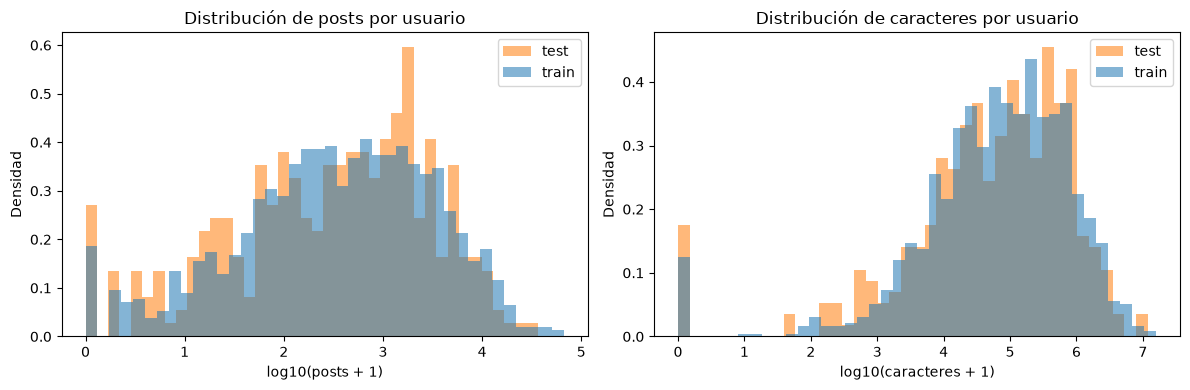

In [5]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

colores = {"train": "tab:blue", "test": "tab:orange"}

for grupo, datos in volumen.groupby("grupo"):
    ejes[0].hist(
        np.log10(datos["posts"] + 1),
        bins=40,
        alpha=0.55,
        density=True,
        label=grupo,
        color=colores[grupo],
    )
    ejes[1].hist(
        np.log10(datos["caracteres"] + 1),
        bins=40,
        alpha=0.55,
        density=True,
        label=grupo,
        color=colores[grupo],
    )

ejes[0].set_title("Distribución de posts por usuario")
ejes[0].set_xlabel("log10(posts + 1)")
ejes[0].set_ylabel("Densidad")
ejes[0].legend()

ejes[1].set_title("Distribución de caracteres por usuario")
ejes[1].set_xlabel("log10(caracteres + 1)")
ejes[1].set_ylabel("Densidad")
ejes[1].legend()

plt.tight_layout()
plt.show()

### Interpretación de la distribución

Las distribuciones de train y test se solapan ampliamente. Test presenta
algo más de densidad entre los usuarios con muy pocos posts y caracteres,
mientras que train alcanza valores extremos mayores.

La escala logarítmica muestra que el volumen varía varios órdenes de
magnitud. Esto refuerza la necesidad de medir resultados por tramos de
volumen y de limitar el coste de los usuarios extremadamente activos.

No parece necesario tratar train y test con procesos distintos, pero las
estrategias deben funcionar bien con usuarios escasos y no depender de la
cola extrema de train.

In [6]:
nombres_ruido = [
    "Vacío o solo espacios",
    "[deleted]",
    "[removed]",
    "Contiene URL",
    "Contiene cita con >",
    "Contiene markdown explícito",
]

metricas_ruido = {
    nombre: {
        "posts": 0,
        "caracteres": 0,
        "usuarios": set(),
    }
    for nombre in nombres_ruido
}

usuarios_ordenados = sorted(usuarios_esperados)
codigo_usuario = {
    usuario: codigo
    for codigo, usuario in enumerate(usuarios_ordenados)
}

partes_codigos = []
partes_huellas = []
partes_utiles = []

inicio = perf_counter()

for lote in parquet.iter_batches(
    batch_size=100_000,
    columns=["username", "body"],
):
    bloque = lote.to_pandas()
    cuerpos = bloque["body"].fillna("").astype(str)
    limpios = cuerpos.str.strip()
    minusculas = limpios.str.lower()
    n_chars = cuerpos.str.len()

    codigos = bloque["username"].map(codigo_usuario)
    assert codigos.notna().all()

    vacio = limpios.eq("")
    eliminado = minusculas.eq("[deleted]")
    retirado = minusculas.eq("[removed]")
    url = cuerpos.str.contains(
        r"https?://|www\.",
        case=False,
        regex=True,
    )
    cita = cuerpos.str.contains(
        r"(?m)^\s*>",
        regex=True,
    )
    markdown = cuerpos.str.contains(
        r"(?m)(?:^\s{0,3}#{1,6}\s|```|`[^`\n]+`|\[[^\]\n]+\]\([^)]+\))",
        regex=True,
    )

    mascaras = {
        "Vacío o solo espacios": vacio,
        "[deleted]": eliminado,
        "[removed]": retirado,
        "Contiene URL": url,
        "Contiene cita con >": cita,
        "Contiene markdown explícito": markdown,
    }

    for nombre, mascara in mascaras.items():
        metricas_ruido[nombre]["posts"] += int(mascara.sum())
        metricas_ruido[nombre]["caracteres"] += int(
            n_chars[mascara].sum()
        )
        metricas_ruido[nombre]["usuarios"].update(
            codigos[mascara].astype(int).unique().tolist()
        )

    util = ~(vacio | eliminado | retirado)

    partes_codigos.append(
        codigos.to_numpy(dtype=np.int16, copy=True)
    )
    partes_huellas.append(
        pd.util.hash_pandas_object(
            cuerpos,
            index=False,
        ).to_numpy(dtype=np.uint64, copy=True)
    )
    partes_utiles.append(
        util.to_numpy(dtype=bool, copy=True)
    )

total_posts = parquet.metadata.num_rows
total_caracteres = int(volumen["caracteres"].sum())

ruido_basico = pd.DataFrame([
    {
        "señal": nombre,
        "posts": datos["posts"],
        "% posts": 100 * datos["posts"] / total_posts,
        "usuarios": len(datos["usuarios"]),
        "% usuarios": 100 * len(datos["usuarios"]) / len(volumen),
        "% caracteres": (
            100 * datos["caracteres"] / total_caracteres
            if total_caracteres
            else 0
        ),
    }
    for nombre, datos in metricas_ruido.items()
]).set_index("señal").round(2)

print(f"Tiempo del análisis: {perf_counter() - inicio:.1f} segundos")
ruido_basico

Tiempo del análisis: 30.5 segundos


,posts,% posts,usuarios,% usuarios,% caracteres
señal,,,,,
Vacío o solo espacios,53,0.00,28,1.74,0.00
[deleted],27,0.00,16,0.99,0.00
[removed],18,0.00,11,0.68,0.00
Contiene URL,166359,5.32,1353,83.99,10.87
Contiene cita con >,0,0.00,0,0.00,0.00
Contiene markdown explícito,117436,3.76,1088,67.54,8.59


### Interpretación: ruido básico

Los vacíos y marcadores `[deleted]`/`[removed]` son residuales y pueden
eliminarse sin impacto apreciable.

Las URLs son frecuentes: afectan a 166.359 posts y a 1.353 usuarios.
Como representan además el 10,87 % de los caracteres, eliminar el post
completo descartaría mucho texto útil. La regla propuesta es sustituir
cada URL por un token como `URL`, conservando el resto del post.

El markdown explícito afecta a 117.436 posts y a 1.088 usuarios. Se
propone normalizar sus marcas y conservar el contenido textual.

No se han detectado líneas que empiecen literalmente por `>`. Antes de
interpretarlo hay que comprobar si el texto citado está codificado como
`&gt;` u otra entidad HTML.

Las categorías se solapan, por lo que sus porcentajes no deben sumarse.

In [7]:
huellas = pd.DataFrame({
    "usuario": np.concatenate(partes_codigos),
    "texto": np.concatenate(partes_huellas),
    "util": np.concatenate(partes_utiles),
})

assert len(huellas) == total_posts

huellas_utiles = huellas.loc[huellas["util"]].copy()

# Repeticiones del mismo texto dentro de un mismo usuario.
conteos_usuario_texto = (
    huellas_utiles
    .groupby(["usuario", "texto"], sort=False)
    .size()
)
grupos_repetidos_usuario = conteos_usuario_texto[
    conteos_usuario_texto > 1
]

posts_en_grupos_usuario = int(grupos_repetidos_usuario.sum())
copias_extra_usuario = int(
    (grupos_repetidos_usuario - 1).sum()
)
usuarios_afectados_usuario = int(
    grupos_repetidos_usuario.index
    .get_level_values("usuario")
    .nunique()
)

# Repeticiones entre cualquier usuario.
conteos_globales = (
    huellas_utiles
    .groupby("texto", sort=False)["usuario"]
    .agg(posts="size", usuarios="nunique")
)
grupos_repetidos_globales = conteos_globales[
    conteos_globales["posts"] > 1
]
grupos_compartidos_usuarios = conteos_globales[
    conteos_globales["usuarios"] > 1
]

posts_en_grupos_globales = int(
    grupos_repetidos_globales["posts"].sum()
)
copias_extra_globales = int(
    (grupos_repetidos_globales["posts"] - 1).sum()
)

huellas_compartidas = set(
    grupos_compartidos_usuarios.index.to_numpy()
)
mascara_compartidos = huellas_utiles["texto"].isin(
    huellas_compartidas
)
usuarios_afectados_globales = int(
    huellas_utiles.loc[mascara_compartidos, "usuario"].nunique()
)

resumen_duplicados = pd.DataFrame({
    "medida": [
        "Posts en grupos repetidos dentro del mismo usuario",
        "Copias extra dentro del mismo usuario",
        "Posts en grupos repetidos globalmente",
        "Copias extra globales",
        "Textos compartidos por más de un usuario",
    ],
    "posts o textos": [
        posts_en_grupos_usuario,
        copias_extra_usuario,
        posts_en_grupos_globales,
        copias_extra_globales,
        len(grupos_compartidos_usuarios),
    ],
    "% de posts útiles": [
        100 * posts_en_grupos_usuario / len(huellas_utiles),
        100 * copias_extra_usuario / len(huellas_utiles),
        100 * posts_en_grupos_globales / len(huellas_utiles),
        100 * copias_extra_globales / len(huellas_utiles),
        np.nan,
    ],
    "usuarios afectados": [
        usuarios_afectados_usuario,
        usuarios_afectados_usuario,
        usuarios_afectados_globales,
        usuarios_afectados_globales,
        usuarios_afectados_globales,
    ],
}).set_index("medida").round(2)

resumen_duplicados

,posts o textos,% de posts útiles,usuarios afectados
medida,,,
Posts en grupos repetidos dentro del mismo usuario,544860,17.43,1033
Copias extra dentro del mismo usuario,306819,9.82,1033
Posts en grupos repetidos globalmente,594636,19.03,1312
Copias extra globales,358548,11.47,1312
Textos compartidos por más de un usuario,15730,NaN,1312


### Interpretación: duplicados exactos

El 17,43 % de los posts útiles pertenece a un grupo repetido dentro del
mismo usuario. Si se conserva una sola copia de cada texto, se eliminarían
306.819 posts, el 9,82 % del total útil, y la regla afectaría a 1.033
usuarios.

Globalmente las copias extra representan el 11,47 %. La diferencia frente
al 9,82 % interno es pequeña y puede incluir respuestas breves y comunes
entre personas, además de copypastas reales.

**Regla provisional:** eliminar duplicados exactos dentro de cada usuario,
conservando la primera aparición. No se propone deduplicar automáticamente
entre usuarios, porque dos personas pueden escribir legítimamente la misma
respuesta corta.

Antes de fijar la regla se analizarán la longitud de los textos repetidos
y los usuarios con tasas extremas de repetición.

In [8]:
duplicacion_usuario = (
    huellas_utiles
    .groupby("usuario")["texto"]
    .agg(posts_utiles="size", textos_unicos="nunique")
)

duplicacion_usuario["copias_extra"] = (
    duplicacion_usuario["posts_utiles"]
    - duplicacion_usuario["textos_unicos"]
)
duplicacion_usuario["% duplicado"] = (
    100
    * duplicacion_usuario["copias_extra"]
    / duplicacion_usuario["posts_utiles"]
)

grupo_por_codigo = {
    codigo: (
        "train"
        if usuario in usuarios_train
        else "test"
    )
    for codigo, usuario in enumerate(usuarios_ordenados)
}

duplicacion_usuario["grupo"] = (
    duplicacion_usuario.index.map(grupo_por_codigo)
)
duplicacion_usuario["usuario_anonimo"] = [
    f"u_{codigo:04d}"
    for codigo in duplicacion_usuario.index
]

resumen_tasas = pd.DataFrame({
    "medida": [
        "Mediana",
        "Percentil 75",
        "Percentil 90",
        "Percentil 95",
        "Percentil 99",
        "Usuarios con ≥10 % duplicado",
        "Usuarios con ≥25 % duplicado",
        "Usuarios con ≥50 % duplicado",
    ],
    "valor": [
        duplicacion_usuario["% duplicado"].median(),
        duplicacion_usuario["% duplicado"].quantile(0.75),
        duplicacion_usuario["% duplicado"].quantile(0.90),
        duplicacion_usuario["% duplicado"].quantile(0.95),
        duplicacion_usuario["% duplicado"].quantile(0.99),
        int((duplicacion_usuario["% duplicado"] >= 10).sum()),
        int((duplicacion_usuario["% duplicado"] >= 25).sum()),
        int((duplicacion_usuario["% duplicado"] >= 50).sum()),
    ],
}).set_index("medida").round(2)

usuarios_extremos = (
    duplicacion_usuario
    .loc[duplicacion_usuario["posts_utiles"] >= 100]
    .sort_values(
        ["% duplicado", "posts_utiles"],
        ascending=False,
    )
    [[
        "usuario_anonimo",
        "grupo",
        "posts_utiles",
        "textos_unicos",
        "copias_extra",
        "% duplicado",
    ]]
    .head(15)
    .set_index("usuario_anonimo")
    .round(2)
)

print("Distribución de tasas de duplicación:")
display(resumen_tasas)

print("Mayores tasas entre usuarios con al menos 100 posts:")
usuarios_extremos

Distribución de tasas de duplicación:


,valor
medida,
Mediana,0.58
Percentil 75,2.56
Percentil 90,19.50
Percentil 95,28.33
Percentil 99,39.74
Usuarios con ≥10 % duplicado,253.00
Usuarios con ≥25 % duplicado,101.00
Usuarios con ≥50 % duplicado,5.00


Mayores tasas entre usuarios con al menos 100 posts:


,grupo,posts_utiles,textos_unicos,copias_extra,% duplicado
usuario_anonimo,,,,,
u_0574,train,557,211,346,62.12
u_0797,train,197,87,110,55.84
u_0274,train,3042,1479,1563,51.38
u_0188,test,3152,1541,1611,51.11
u_1381,train,1407,716,691,49.11
u_0670,train,501,255,246,49.10
u_0811,train,6368,3342,3026,47.52
u_0775,train,1192,659,533,44.71
u_0061,train,131,74,57,43.51


### Interpretación: concentración de duplicados

La mayoría de usuarios apenas repite contenido: la mediana es 0,58 % y
el percentil 75 es 2,56 %. El problema está concentrado en una minoría:
253 usuarios superan el 10 %, 101 superan el 25 % y solo cinco superan
el 50 %.

Esto no demuestra por sí solo que sean bots. Puede deberse a respuestas
breves repetidas, plantillas, copypastas o actividad automatizada. La
deduplicación dentro de cada usuario reduciría especialmente el peso de
estos casos sin eliminar al usuario ni asumir su causa.

Hay casos extremos tanto en train como en test, por lo que la regla debe
aplicarse de la misma forma en ambos conjuntos.

In [9]:
huellas_repetidas = {
    int(valor)
    for valor in grupos_repetidos_globales.index
}

longitud_por_huella = {}

metricas_citas = {
    "Línea que empieza por >": {
        "posts": 0,
        "usuarios": set(),
    },
    "Línea que empieza por &gt;": {
        "posts": 0,
        "usuarios": set(),
    },
    "Contiene &gt; en cualquier posición": {
        "posts": 0,
        "usuarios": set(),
    },
    "Contiene &amp;gt;": {
        "posts": 0,
        "usuarios": set(),
    },
}

inicio = perf_counter()

for lote in parquet.iter_batches(
    batch_size=100_000,
    columns=["username", "body"],
):
    bloque = lote.to_pandas()
    cuerpos = bloque["body"].fillna("").astype(str)
    codigos = (
        bloque["username"]
        .map(codigo_usuario)
        .astype(int)
    )

    hashes = pd.util.hash_pandas_object(
        cuerpos,
        index=False,
    ).to_numpy(dtype=np.uint64)

    mascara_repetida = (
        pd.Series(hashes)
        .isin(huellas_repetidas)
        .to_numpy()
    )

    if mascara_repetida.any():
        longitudes_repetidas = pd.DataFrame({
            "texto": hashes[mascara_repetida],
            "longitud": cuerpos.str.len().to_numpy()[
                mascara_repetida
            ],
        }).drop_duplicates("texto")

        claves = [
            int(valor)
            for valor in longitudes_repetidas[
                "texto"
            ].to_numpy()
        ]
        valores = [
            int(valor)
            for valor in longitudes_repetidas[
                "longitud"
            ].to_numpy()
        ]

        longitud_por_huella.update(
            dict(zip(claves, valores))
        )

    mascaras_citas = {
        "Línea que empieza por >": cuerpos.str.contains(
            r"(?m)^\s*>",
            regex=True,
        ),
        "Línea que empieza por &gt;": cuerpos.str.contains(
            r"(?mi)^\s*&gt;",
            regex=True,
        ),
        "Contiene &gt; en cualquier posición": cuerpos.str.contains(
            r"(?i)&gt;",
            regex=True,
        ),
        "Contiene &amp;gt;": cuerpos.str.contains(
            r"(?i)&amp;gt;",
            regex=True,
        ),
    }

    for nombre, mascara in mascaras_citas.items():
        metricas_citas[nombre]["posts"] += int(
            mascara.sum()
        )
        metricas_citas[nombre]["usuarios"].update(
            codigos[mascara].unique().tolist()
        )

tabla_citas = pd.DataFrame([
    {
        "señal": nombre,
        "posts": datos["posts"],
        "% posts": (
            100 * datos["posts"] / total_posts
        ),
        "usuarios": len(datos["usuarios"]),
        "% usuarios": (
            100
            * len(datos["usuarios"])
            / len(volumen)
        ),
    }
    for nombre, datos in metricas_citas.items()
]).set_index("señal").round(2)

duplicados_dentro = (
    grupos_repetidos_usuario
    .rename("repeticiones")
    .reset_index()
)

duplicados_dentro["longitud"] = (
    duplicados_dentro["texto"]
    .map(longitud_por_huella)
)

duplicados_dentro["copias_extra"] = (
    duplicados_dentro["repeticiones"] - 1
)

duplicados_global = (
    grupos_repetidos_globales
    .reset_index()
)

duplicados_global["longitud"] = (
    duplicados_global["texto"]
    .map(longitud_por_huella)
)

duplicados_global["copias_extra"] = (
    duplicados_global["posts"] - 1
)

assert duplicados_dentro["longitud"].notna().all()
assert duplicados_global["longitud"].notna().all()

limites = [
    -1,
    10,
    25,
    50,
    100,
    250,
    1000,
    np.inf,
]

etiquetas = [
    "0-10",
    "11-25",
    "26-50",
    "51-100",
    "101-250",
    "251-1000",
    ">1000",
]

duplicados_dentro["tramo"] = pd.cut(
    duplicados_dentro["longitud"],
    bins=limites,
    labels=etiquetas,
)

duplicados_global["tramo"] = pd.cut(
    duplicados_global["longitud"],
    bins=limites,
    labels=etiquetas,
)

resumen_longitud_dentro = (
    duplicados_dentro
    .groupby("tramo", observed=True)
    .agg(
        textos_distintos=("texto", "size"),
        posts=("repeticiones", "sum"),
        copias_extra=("copias_extra", "sum"),
    )
)

compartidos = duplicados_global.loc[
    duplicados_global["usuarios"] > 1
]

resumen_longitud_compartidos = (
    compartidos
    .groupby("tramo", observed=True)
    .agg(
        textos_distintos=("texto", "size"),
        posts=("posts", "sum"),
        copias_extra=("copias_extra", "sum"),
        max_usuarios=("usuarios", "max"),
    )
)

assert (
    resumen_longitud_dentro["copias_extra"].sum()
    == copias_extra_usuario
)

print(
    f"Tiempo: {perf_counter() - inicio:.1f} segundos"
)

print("Citas:")
display(tabla_citas)

print(
    "Duplicados dentro del mismo usuario, "
    "por longitud:"
)
display(resumen_longitud_dentro)

print(
    "Textos compartidos entre usuarios, "
    "por longitud:"
)
display(resumen_longitud_compartidos)

Tiempo: 28.1 segundos
Citas:


,posts,% posts,usuarios,% usuarios
señal,,,,
Línea que empieza por >,0,0.00,0,0.00
Línea que empieza por &gt;,173,0.01,106,6.58
Contiene &gt; en cualquier posición,14897,0.48,867,53.82
Contiene &amp;gt;,57,0.00,19,1.18


Duplicados dentro del mismo usuario, por longitud:


,textos_distintos,posts,copias_extra
tramo,,,
0-10,19305,85293,65988
11-25,27485,69559,42074
26-50,35603,73567,37964
51-100,45704,93060,47356
101-250,58559,119250,60691
251-1000,44510,89882,45372
>1000,6875,14249,7374


Textos compartidos entre usuarios, por longitud:


,textos_distintos,posts,copias_extra,max_usuarios
tramo,,,,
0-10,7836,96728,88892,318
11-25,7037,35473,28436,83
26-50,777,2409,1632,16
51-100,52,141,89,5
101-250,14,35,21,3
251-1000,9,29,20,4
>1000,5,21,16,8


### Interpretación: longitud de duplicados y citas

Los duplicados dentro de un mismo usuario aparecen en todos los tramos
de longitud. Más de la mitad de las copias extra supera 50 caracteres y
7.374 superan 1.000 caracteres. Por tanto, el fenómeno no se explica
solo por respuestas breves como “yes” o “thanks”; hay contenido
sustancial repetido y la deduplicación interna está justificada.

Entre usuarios distintos ocurre lo contrario: casi todas las copias
compartidas tienen 25 caracteres o menos. Los textos largos compartidos
son excepcionales. Esto refuerza la decisión de no deduplicar entre
usuarios, ya que se eliminarían principalmente respuestas cortas
legítimas.

Solo 173 posts comienzan por una cita codificada como `&gt;`, aunque
106 usuarios tienen al menos una. La regla adecuada sería decodificar
primero las entidades HTML y después eliminar únicamente las líneas
citadas, conservando el texto propio. El impacto total sería muy pequeño.

Los cinco usuarios con más del 50 % de duplicados deben considerarse
casos extremos o posibles automatizaciones, pero no se eliminarán sin
más evidencia.

## Idioma

El idioma se estima con una muestra reproducible de hasta 10 posts por
usuario, utilizando únicamente textos de al menos 50 caracteres. Esta
muestra evita que los usuarios extremadamente activos dominen el cálculo.

`langdetect` es una aproximación y puede fallar con textos breves, jerga,
emojis o contenido multilingüe. Se consideran resultados seguros solo
cuando la probabilidad estimada es al menos 0,8.

In [10]:
from langdetect import (
    DetectorFactory,
    LangDetectException,
    detect_langs,
)

DetectorFactory.seed = SEED

MAX_POSTS_IDIOMA = 10
MIN_CARACTERES_IDIOMA = 50

rng_idioma = np.random.default_rng(SEED + 21)
partes_idioma = []

inicio = perf_counter()

for lote in parquet.iter_batches(
    batch_size=100_000,
    columns=["username", "body"],
):
    bloque = lote.to_pandas()
    bloque["body"] = bloque["body"].fillna("").astype(str)

    bloque = bloque.loc[
        bloque["username"].isin(usuarios_esperados)
        & bloque["body"].str.strip().str.len().ge(
            MIN_CARACTERES_IDIOMA
        )
    ].copy()

    bloque["_azar"] = rng_idioma.random(len(bloque))

    partes_idioma.append(
        bloque.sort_values("_azar")
        .groupby("username", sort=False)
        .head(MAX_POSTS_IDIOMA)
    )

muestra_idioma = (
    pd.concat(partes_idioma, ignore_index=True)
    .sort_values("_azar")
    .groupby("username", sort=False)
    .head(MAX_POSTS_IDIOMA)
    .reset_index(drop=True)
)

def detectar_idioma(texto):
    try:
        candidatos = detect_langs(str(texto)[:5000])
        mejor = candidatos[0]
        return mejor.lang, float(mejor.prob)
    except LangDetectException:
        return "desconocido", 0.0

resultados_posts = [
    detectar_idioma(texto)
    for texto in muestra_idioma["body"]
]

muestra_idioma[["idioma", "probabilidad"]] = pd.DataFrame(
    resultados_posts,
    index=muestra_idioma.index,
)

muestra_idioma["clasificacion"] = np.select(
    [
        (muestra_idioma["idioma"] == "en")
        & (muestra_idioma["probabilidad"] >= 0.8),
        (muestra_idioma["idioma"] != "en")
        & (muestra_idioma["idioma"] != "desconocido")
        & (muestra_idioma["probabilidad"] >= 0.8),
    ],
    [
        "inglés seguro",
        "no inglés seguro",
    ],
    default="incierto",
)

# Una segunda estimación con los posts concatenados por usuario.
textos_idioma_usuario = (
    muestra_idioma
    .groupby("username")["body"]
    .agg("\n".join)
)

resultados_usuarios = [
    detectar_idioma(texto)
    for texto in textos_idioma_usuario
]

idioma_usuarios = pd.DataFrame(
    resultados_usuarios,
    index=textos_idioma_usuario.index,
    columns=["idioma", "probabilidad"],
)

idioma_usuarios["grupo"] = np.where(
    idioma_usuarios.index.isin(usuarios_train),
    "train",
    "test",
)

idioma_usuarios["clasificacion"] = np.select(
    [
        (idioma_usuarios["idioma"] == "en")
        & (idioma_usuarios["probabilidad"] >= 0.8),
        (idioma_usuarios["idioma"] != "en")
        & (idioma_usuarios["idioma"] != "desconocido")
        & (idioma_usuarios["probabilidad"] >= 0.8),
    ],
    [
        "inglés seguro",
        "no inglés seguro",
    ],
    default="incierto",
)

tabla_posts_idioma = pd.crosstab(
    muestra_idioma["clasificacion"],
    columns="posts",
)
tabla_posts_idioma["%"] = (
    100
    * tabla_posts_idioma["posts"]
    / len(muestra_idioma)
)

tabla_usuarios_idioma = pd.crosstab(
    idioma_usuarios["grupo"],
    idioma_usuarios["clasificacion"],
)
tabla_usuarios_idioma["sin muestra"] = [
    len(usuarios_test - set(idioma_usuarios.index)),
    len(usuarios_train - set(idioma_usuarios.index)),
]

idiomas_no_ingles = (
    idioma_usuarios.loc[
        idioma_usuarios["clasificacion"] == "no inglés seguro",
        "idioma",
    ]
    .value_counts()
    .head(10)
    .rename("usuarios")
    .to_frame()
)

print(f"Tiempo: {perf_counter() - inicio:.1f} segundos")
print("Posts analizados:", len(muestra_idioma))
print("Usuarios con muestra:", len(idioma_usuarios))

print("Clasificación de posts:")
display(tabla_posts_idioma.round(2))

print("Clasificación por usuario:")
display(tabla_usuarios_idioma)

print("Idiomas no ingleses más frecuentes:")
idiomas_no_ingles

Tiempo: 69.5 segundos
Posts analizados: 14967
Usuarios con muestra: 1565
Clasificación de posts:


col_0,posts,%
clasificacion,,
incierto,143,0.96
inglés seguro,14554,97.24
no inglés seguro,270,1.80


Clasificación por usuario:


clasificacion,incierto,inglés seguro,no inglés seguro,sin muestra
grupo,,,,
test,0,306,5,12
train,10,1233,11,34


Idiomas no ingleses más frecuentes:


,usuarios
idioma,
nl,3
sv,3
fr,3
de,2
no,1
pt,1
el,1
pl,1
fi,1


### Interpretación: idioma

El corpus es predominantemente inglés. En la muestra equilibrada,
el 97,24 % de los posts se detecta como inglés con confianza alta y
solo el 1,80 % como otro idioma.

A nivel de usuario, 16 de los 1.565 usuarios con texto suficiente
parecen escribir principalmente en otro idioma. Train y test presentan
el mismo patrón general. Los 46 usuarios sin muestra incluyen los 39
sin posts y algunos cuyos textos son demasiado breves para esta prueba.

Los idiomas no ingleses están repartidos y ninguno domina claramente.
Dado su bajo volumen y la incertidumbre del detector, no se propone
eliminar estos usuarios ni sus posts.

**Implicación:** el inglés puede seguir siendo el idioma principal de
los modelos, pero conviene conservar los textos no ingleses y registrar
el idioma como posible señal o usar modelos multilingües si se explora
esta línea. Esta estimación procede de una muestra, no de todos los posts.

In [11]:
from scipy.stats import spearmanr

analisis_train = (
    train.set_index("username")
    .join(volumen[["posts", "caracteres"]])
)

analisis_train["log_posts"] = np.log1p(
    analisis_train["posts"]
)
analisis_train["log_caracteres"] = np.log1p(
    analisis_train["caracteres"]
)

variables_volumen = {
    "log(posts + 1)": "log_posts",
    "log(caracteres + 1)": "log_caracteres",
}

correlaciones = pd.DataFrame(
    index=variables_volumen,
    columns=TRAITS,
    dtype=float,
)
p_valores = correlaciones.copy()

for etiqueta, variable in variables_volumen.items():
    for rasgo in TRAITS:
        datos = analisis_train[[variable, rasgo]].dropna()
        rho, p = spearmanr(
            datos[variable],
            datos[rasgo],
        )
        correlaciones.loc[etiqueta, rasgo] = rho
        p_valores.loc[etiqueta, rasgo] = p

# Tramos de volumen para comprobar posibles relaciones no lineales.
analisis_train["tramo_posts"] = "sin posts"

con_posts = analisis_train["posts"] > 0
analisis_train.loc[con_posts, "tramo_posts"] = pd.qcut(
    analisis_train.loc[con_posts, "posts"],
    q=5,
    labels=[
        "Q1 menos posts",
        "Q2",
        "Q3",
        "Q4",
        "Q5 más posts",
    ],
).astype(str)

medias_por_volumen = (
    analisis_train
    .groupby("tramo_posts")[[*TRAITS]]
    .mean()
    .round(2)
)

medias_por_volumen.insert(
    0,
    "usuarios",
    analisis_train.groupby("tramo_posts").size(),
)

orden_tramos = [
    "sin posts",
    "Q1 menos posts",
    "Q2",
    "Q3",
    "Q4",
    "Q5 más posts",
]
medias_por_volumen = medias_por_volumen.reindex(orden_tramos)

print("Correlaciones de Spearman:")
display(correlaciones.round(3))

print("Valores p exploratorios, sin corrección por comparaciones:")
display(p_valores.round(4))

print("Medias de los rasgos por tramo de volumen:")
medias_por_volumen

Correlaciones de Spearman:


,agreeableness,openness,conscientiousness,extraversion,neuroticism
log(posts + 1),-0.004,-0.014,0.022,-0.022,-0.014
log(caracteres + 1),0.014,0.018,0.026,-0.018,-0.027


Valores p exploratorios, sin corrección por comparaciones:


,agreeableness,openness,conscientiousness,extraversion,neuroticism
log(posts + 1),0.8921,0.6259,0.4245,0.4228,0.6041
log(caracteres + 1),0.6069,0.5271,0.3565,0.5079,0.3302


Medias de los rasgos por tramo de volumen:


,usuarios,agreeableness,openness,conscientiousness,extraversion,neuroticism
tramo_posts,,,,,,
sin posts,29,41.24,59.86,34.21,35.79,59.28
Q1 menos posts,254,42.64,61.78,38.29,39.23,49.17
Q2,251,45.47,62.12,41.92,39.00,48.53
Q3,250,40.89,63.97,37.10,35.29,50.12
Q4,252,40.69,63.62,40.82,35.41,50.72
Q5 más posts,252,44.36,61.75,39.84,37.53,48.89


### Interpretación: volumen y rasgos

No se observa una relación monotónica relevante entre el volumen de
texto y ninguno de los cinco rasgos. Todas las correlaciones de Spearman
están entre -0,027 y 0,026, con valores p superiores a 0,33.

Las medias por quintiles tampoco siguen una tendencia consistente. El
grupo sin posts contiene solo 29 usuarios de train, por lo que sus medias
son inestables y no deben interpretarse como una relación real.

**Implicación:** el número de posts o caracteres no parece útil como
señal directa para subir o bajar una predicción de personalidad. Sí puede
ser útil como medida de confianza: con poco texto, conviene estudiar una
mezcla mayor con la media; con mucho texto, limitar o muestrear posts
reduce coste sin introducir una dirección artificial en los rasgos.

Estas decisiones se han explorado mirando todo train, por lo que cualquier
estrategia derivada deberá evaluarse después con la validación cruzada
común y declararse en `ANALISIS.md`.

## Conclusiones y propuestas

### Reglas de limpieza propuestas para #7

1. **Eliminar vacíos y marcadores.** Quitar los 53 posts vacíos, los
   27 `[deleted]` y los 18 `[removed]`. El impacto es residual.

2. **Deduplicar dentro de cada usuario.** Conservar una aparición de
   cada texto exacto. Eliminaría 306.819 copias extra, el 9,82 % de los
   posts útiles, y afectaría a 1.033 usuarios. Los duplicados incluyen
   textos largos, por lo que no son solo respuestas breves.

3. **No deduplicar entre usuarios.** Casi todos los textos compartidos
   entre personas tienen 25 caracteres o menos y parecen respuestas
   genéricas. La deduplicación global eliminaría contenido legítimo.

4. **Normalizar URLs.** Sustituir cada URL por un token `URL`, conservando
   el resto del post. Las URLs afectan a 166.359 posts y a 1.353 usuarios;
   eliminar esos posts descartaría demasiado texto.

5. **Normalizar markdown y HTML.** Decodificar entidades HTML y retirar
   marcas de enlaces, código y títulos conservando el contenido. El
   markdown explícito afecta a 117.436 posts y 1.088 usuarios.

6. **Tratar las citas de forma conservadora.** Después de decodificar
   HTML, eliminar únicamente las líneas que empiezan por `>`. Se han
   detectado 173 posts con esa forma codificada como `&gt;`.

7. **Conservar otros idiomas.** El 1,80 % de la muestra de posts se
   detecta como no inglés seguro y solo 16 usuarios parecen escribir
   principalmente en otro idioma. El detector es aproximado y no
   justifica eliminarlos.

8. **No eliminar posibles bots automáticamente.** Cinco usuarios superan
   el 50 % de duplicación. La deduplicación reduce su peso; excluirlos
   necesitaría evidencia adicional.

### Implicaciones para la estrategia

- Los 39 usuarios sin posts necesitan una predicción alternativa, como
  la media de entrenamiento.
- Entre el 20 % y el 22 % de usuarios tiene como máximo 50 posts. Debe
  medirse si mezclar con la media según el volumen mejora el RMSE.
- El volumen no se relaciona directamente con los rasgos; debe usarse
  como medida de confianza, no como dirección de la predicción.
- La cola extrema justifica limitar o muestrear posts por usuario para
  controlar coste. El límite debe compararse experimentalmente.
- La limpieza debe aplicarse igual a train y test.
- Cualquier estrategia decidida a partir de este análisis puede producir
  una validación algo optimista porque se ha diseñado mirando todo train.
  Debe declararse y evaluarse con `validacion_cruzada`.

### Limitaciones

- El idioma se estimó con hasta 10 posts de al menos 50 caracteres por
  usuario, no con los 3,1 millones de posts.
- Los posibles bots se identificaron solo mediante repetición exacta.
- No se inspeccionaron textos completos en el notebook para evitar subir
  datos originales al repositorio.